In [2]:
# Gerekli kütüphanelerin yüklenmesi
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, LabelEncoder

# 1. Veri Setini Okuma
df = pd.read_csv('heart.csv')

print("Veri Setinin İlk Hali:")
display(df.head())

Veri Setinin İlk Hali:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
# --- ADIM 1: EKSİK VERİ KONTROLÜ VE DOLDURMA ---
# NOT: Heart veri setinde 'Cholesterol' değeri 0 olanlar aslında eksik veridir.
df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)

# --- DOLULUK ORANI HESAPLAMA ---
print("\n--- Veri Seti Doluluk Oranları ---")
doluluk_oranlari = df.count() / len(df) * 100

doluluk_tablosu = pd.DataFrame({
    'Toplam Veri': len(df),
    'Dolu Veri': df.count(),
    'Eksik Veri': df.isna().sum(),
    'Doluluk Oranı (%)': doluluk_oranlari
})

print(doluluk_tablosu.sort_values(by='Doluluk Oranı (%)', ascending=False))
print("-" * 40)

# Eksik verilerin ortalama ile doldurulması
cholesterol_mean = df['Cholesterol'].mean()

# --- DÜZELTME: Atama yöntemi ile doldurma ---
df['Cholesterol'] = df['Cholesterol'].fillna(cholesterol_mean)

print(f"\nCholesterol eksik verileri ortalama ({cholesterol_mean:.2f}) ile dolduruldu.")


--- Veri Seti Doluluk Oranları ---
                Toplam Veri  Dolu Veri  Eksik Veri  Doluluk Oranı (%)
Age                     918        918           0         100.000000
Sex                     918        918           0         100.000000
ChestPainType           918        918           0         100.000000
RestingBP               918        918           0         100.000000
FastingBS               918        918           0         100.000000
RestingECG              918        918           0         100.000000
MaxHR                   918        918           0         100.000000
ExerciseAngina          918        918           0         100.000000
ST_Slope                918        918           0         100.000000
Oldpeak                 918        918           0         100.000000
HeartDisease            918        918           0         100.000000
Cholesterol             918        746         172          81.263617
----------------------------------------

Cholesterol 

In [4]:
# --- ADIM 2: GÜRÜLTÜLÜ VERİ VE AYKIRI DEĞER TEMİZLİĞİ ---
# Sadece sayısal sütunlar üzerinde Z-Score hesaplanır
numerical_cols = ['RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak', 'Age']
z_scores = np.abs(stats.zscore(df[numerical_cols]))

# Herhangi bir sütunda 3 standart sapmadan fazla sapma varsa o satırı işaretle
outlier_indices = (z_scores > 3).any(axis=1)

print(f"\nToplam Aykırı Değer Sayısı (Z-Score > 3): {outlier_indices.sum()}")

# Aykırı değerleri veri setinden çıkarıyoruz
# df_cleaned artık bizim temiz veri setimiz oluyor
df_cleaned = df[~outlier_indices].copy()
print(f"Aykırı değerler temizlendikten sonraki satır sayısı: {df_cleaned.shape[0]}")


Toplam Aykırı Değer Sayısı (Z-Score > 3): 28
Aykırı değerler temizlendikten sonraki satır sayısı: 890


In [5]:
# --- ADIM 3: KATEGORİK VERİ DÖNÜŞÜMÜ (ENCODING) ---
le = LabelEncoder()
categorical_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

for col in categorical_cols:
    df_cleaned[col] = le.fit_transform(df_cleaned[col])

print("Kategorik veriler sayısala dönüştürüldü (Label Encoding).")
display(df_cleaned[categorical_cols].head())

Kategorik veriler sayısala dönüştürüldü (Label Encoding).


,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
0,1,1,1,0,2
1,0,2,1,0,1
2,1,1,2,0,2
3,0,0,1,1,1
4,1,2,1,0,2


In [6]:
# --- ADIM 4: NORMALİZASYON ---
scaler = MinMaxScaler()
cols_to_scale = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
df_cleaned[cols_to_scale] = scaler.fit_transform(df_cleaned[cols_to_scale])

print("\nMin-Max Normalizasyonu Sonrası Veri (İlk 5 Satır):")
display(df_cleaned.head())


Min-Max Normalizasyonu Sonrası Veri (İlk 5 Satır):


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,0.244898,1,1,0.571429,0.639498,0,1,0.784173,0,0.333333,2,0
1,0.428571,0,2,0.761905,0.297806,0,1,0.669065,0,0.500000,1,1
2,0.183673,1,1,0.476190,0.620690,0,2,0.251799,0,0.333333,2,0
3,0.408163,0,0,0.552381,0.404389,0,1,0.323741,1,0.583333,1,1
4,0.530612,1,2,0.666667,0.344828,0,1,0.424460,0,0.333333,2,0


In [7]:
# --- ADIM 5: NİTELİK OLUŞTURMA (FEATURE ENGINEERING) ---
bins = [0, 40, 60, 100]
labels = [0, 1, 2] # 0: Genç, 1: Orta, 2: Yaşlı

# Orijinal yaş verisini (df), temizlenmiş verinin (df_cleaned) indeksine göre çekiyoruz
# Çünkü df_cleaned['Age'] yukarıda normalize edildiği için (0-1 arası) onu kullanamayız.
original_ages = df.loc[df_cleaned.index, 'Age']
df_cleaned['Age_Category'] = pd.cut(original_ages, bins=bins, labels=labels)

# Kategorik veriyi int formatına çevir
df_cleaned['Age_Category'] = df_cleaned['Age_Category'].astype(int)

print("Yaş kategorileri oluşturuldu.")
display(df_cleaned[['Age', 'Age_Category']].head())

Yaş kategorileri oluşturuldu.


,Age,Age_Category
0,0.244898,0
1,0.428571,1
2,0.183673,0
3,0.408163,1
4,0.530612,1


In [8]:
print("\nÖnişleme Tamamlandı. Veri Seti Özeti:")
print(df_cleaned.info())

# --- SONUÇ: Makine Öğrenmesi İçin X ve y Ayrımı ---
# Bu kısım bir sonraki aşamaya (Machine Learning) hazırlıktır.
X = df_cleaned.drop('HeartDisease', axis=1)
y = df_cleaned['HeartDisease']

# Temizlenmiş veriyi CSV dosyası olarak kaydetme
df_cleaned.to_csv('heart_onislenmis.csv', index=False)

print("Dosya başarıyla kaydedildi: heart_onislenmis.csv")


Önişleme Tamamlandı. Veri Seti Özeti:
<class 'pandas.core.frame.DataFrame'>
Index: 890 entries, 0 to 917
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             890 non-null    float64
 1   Sex             890 non-null    int64  
 2   ChestPainType   890 non-null    int64  
 3   RestingBP       890 non-null    float64
 4   Cholesterol     890 non-null    float64
 5   FastingBS       890 non-null    int64  
 6   RestingECG      890 non-null    int64  
 7   MaxHR           890 non-null    float64
 8   ExerciseAngina  890 non-null    int64  
 9   Oldpeak         890 non-null    float64
 10  ST_Slope        890 non-null    int64  
 11  HeartDisease    890 non-null    int64  
 12  Age_Category    890 non-null    int64  
dtypes: float64(5), int64(8)
memory usage: 97.3 KB
None
Dosya başarıyla kaydedildi: heart_onislenmis.csv


In [9]:
# Gerekli kütüphanelerin eklenmesi
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd # Özellik önemi kısmında lazım olacak

# --- ADIM 1: Veriyi X (Özellikler) ve y (Hedef) olarak ayırma ---
# df_cleaned, önceki aşamadan gelen temizlenmiş veri setimizdir.
X = df_cleaned.drop('HeartDisease', axis=1)
y = df_cleaned['HeartDisease']

In [10]:
# --- ADIM 2: HOCANIN İSTEDİĞİ ÖZEL AYIRMA İŞLEMİ ---

# 1. Parçalama: Veriyi %90 (İşlenecek Kısım) ve %10 (Kenara Ayrılan/Holdout) olarak bölüyoruz.
# test_size=0.10 diyerek %10'u ayırıyoruz.
X_temp, X_holdout, y_temp, y_holdout = train_test_split(X, y, test_size=0.10, random_state=42)

print(f"Toplam Veri Sayısı: {len(X)}")
print(f"Kenara Ayrılan (%10) Veri Sayısı: {len(X_holdout)}")
print(f"Eğitim/Test İçin Kullanılacak (%90) Veri Sayısı: {len(X_temp)}")

# 2. Parçalama: O %90'lık kısmı (X_temp), kendi içinde %80 Eğitim ve %20 Test olarak bölüyoruz.
# Burada test_size=0.20 kullanıyoruz.
X_train, X_test, y_train, y_test = train_test_split(X_temp, y_temp, test_size=0.20, random_state=42)

print(f"Model Eğitimi İçin Kullanılacak Veri (X_train): {len(X_train)}")
print(f"Model Testi İçin Kullanılacak Veri (X_test): {len(X_test)}")

Toplam Veri Sayısı: 890
Kenara Ayrılan (%10) Veri Sayısı: 89
Eğitim/Test İçin Kullanılacak (%90) Veri Sayısı: 801
Model Eğitimi İçin Kullanılacak Veri (X_train): 640
Model Testi İçin Kullanılacak Veri (X_test): 161


In [11]:
# --- ADIM 3: RANDOM FOREST MODELİ VE CROSS VALIDATION ---
# Random Forest modelini tanımlıyoruz (n_estimators=100 standart bir başlangıçtır)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Cross Validation Uygulaması
# PDF'te belirtildiği gibi modelin genelleme yeteneğini ölçmek için 5 veya 10 katlı doğrulama yapılır.
# cv=5 diyerek veriyi 5 parçaya bölüp deniyoruz.
cv_scores = cross_val_score(rf_model, X_train, y_train, cv=5)

print("\n--- Cross Validation (Çapraz Doğrulama) Sonuçları ---")
print(f"Skorlar: {cv_scores}")
print(f"Ortalama Doğruluk (Accuracy): {cv_scores.mean():.4f}")


--- Cross Validation (Çapraz Doğrulama) Sonuçları ---
Skorlar: [0.8828125 0.8046875 0.875     0.875     0.890625 ]
Ortalama Doğruluk (Accuracy): 0.8656



--- Test Seti Sonuçları ---
Test Seti Doğruluk Oranı (Accuracy): 0.8385

Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.83      0.80      0.81        71
           1       0.85      0.87      0.86        90

    accuracy                           0.84       161
   macro avg       0.84      0.83      0.84       161
weighted avg       0.84      0.84      0.84       161



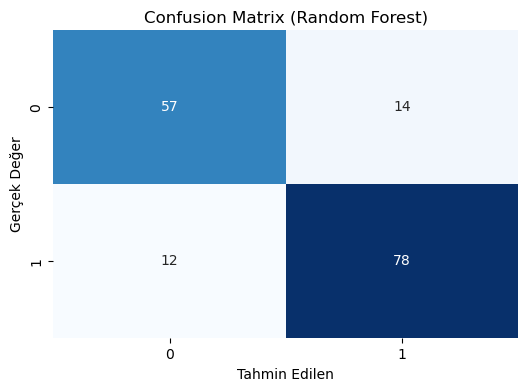

In [12]:
# --- ADIM 4: MODELİN EĞİTİLMESİ VE TEST EDİLMESİ ---
# Modeli eğitim setiyle eğitiyoruz
rf_model.fit(X_train, y_train)

# Test setiyle tahmin yapıyoruz
y_pred = rf_model.predict(X_test)

# --- ADIM 5: SONUÇLARIN RAPORLANMASI (PDF Referanslı) ---
print("\n--- Test Seti Sonuçları ---")
acc = accuracy_score(y_test, y_pred)
print(f"Test Seti Doğruluk Oranı (Accuracy): {acc:.4f}")

print("\nSınıflandırma Raporu:")
print(classification_report(y_test, y_pred))

# Karışıklık Matrisi (Confusion Matrix) Görselleştirme
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Tahmin Edilen')
plt.ylabel('Gerçek Değer')
plt.title('Confusion Matrix (Random Forest)')
plt.show()

In [13]:
# --- ADIM 6: HOLDOUT (KENARA AYRILAN) VERİ İLE FİNAL TESTİ ---
print("\n--- Holdout (Kenara Ayrılan %10) Seti Sonuçları ---")
# Eğitilmiş model ile holdout setini tahmin et
y_holdout_pred = rf_model.predict(X_holdout)

# Başarı oranını yazdır
acc_holdout = accuracy_score(y_holdout, y_holdout_pred)
print(f"Holdout Seti Doğruluk Oranı: {acc_holdout:.4f}")

# İstersen bunun için de ufak bir rapor yazdırabilirsin
print(classification_report(y_holdout, y_holdout_pred))


--- Holdout (Kenara Ayrılan %10) Seti Sonuçları ---
Holdout Seti Doğruluk Oranı: 0.9438
              precision    recall  f1-score   support

           0       0.93      0.95      0.94        40
           1       0.96      0.94      0.95        49

    accuracy                           0.94        89
   macro avg       0.94      0.94      0.94        89
weighted avg       0.94      0.94      0.94        89



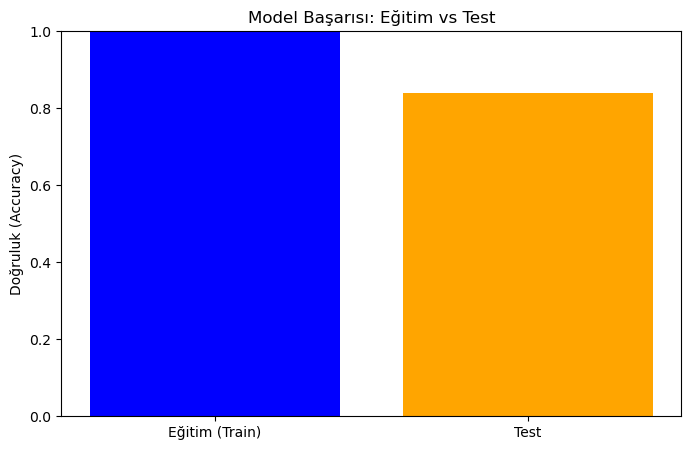

In [14]:
# Eğitim başarısı
train_acc = accuracy_score(y_train, rf_model.predict(X_train))
# Test başarısı (zaten hesaplamıştın: acc)

plt.figure(figsize=(8, 5))
plt.bar(['Eğitim (Train)', 'Test'], [train_acc, acc], color=['blue', 'orange'])
plt.ylim(0, 1)
plt.title('Model Başarısı: Eğitim vs Test')
plt.ylabel('Doğruluk (Accuracy)')
plt.show()

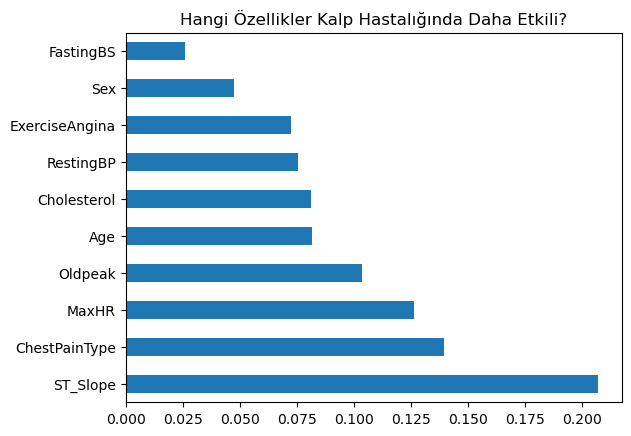

In [15]:
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
feature_importances.nlargest(10).plot(kind='barh')
plt.title("Hangi Özellikler Kalp Hastalığında Daha Etkili?")
plt.show()

In [16]:
# -----------------------------------------------------------------------------
# ADIM 1: GEREKLİ KÜTÜPHANELERİN VE AYARLARIN YÜKLENMESİ
# -----------------------------------------------------------------------------
import warnings
warnings.filterwarnings('ignore')

from IPython.core.display import display, HTML
display(HTML("<style>.container { width:70% ! important; }<style>"))

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Veriyi yüklüyoruz
veri = pd.read_csv("heart_onislenmis.csv")
X = veri.drop('HeartDisease', axis=1)
y = veri['HeartDisease']

In [17]:
# -----------------------------------------------------------------------------
# ADIM 2: VERİ YÜKLEME VE PARÇALAMA (ÇİFT AŞAMALI BÖLME)
# -----------------------------------------------------------------------------

# 1. Parçalama: %10 Saklı Veri (Holdout)
X_gecici, X_sakli, y_gecici, y_sakli = train_test_split(X, y, test_size=0.10, random_state=42)

# 2. Parçalama: %80 Eğitim, %20 Test
X_egitim, X_test, y_egitim, y_test = train_test_split(X_gecici, y_gecici, test_size=0.20, random_state=42)

print(f"Eğitim Verisi Sayısı: {len(X_egitim)}")
print(f"Test Verisi Sayısı: {len(X_test)}")

Eğitim Verisi Sayısı: 640
Test Verisi Sayısı: 161


In [18]:
# -----------------------------------------------------------------------------
# ADIM 3: MODEL KURULUMU VE ÇAPRAZ DOĞRULAMA
# -----------------------------------------------------------------------------

model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

# Çapraz Doğrulama (5 Katlı)
capraz_dogrulama_skorlari = cross_val_score(model, X_egitim, y_egitim, cv=5)

print("\n--- Çapraz Doğrulama (Cross Validation) Sonuçları ---")
temiz_skorlar = [f"{puan:.2f}" for puan in capraz_dogrulama_skorlari]
print(f"5 Farklı Deneme Sonucu: {', '.join(temiz_skorlar)}") 
print(f"Ortalama Başarı Puanı:  {capraz_dogrulama_skorlari.mean():.2f}")


--- Çapraz Doğrulama (Cross Validation) Sonuçları ---
5 Farklı Deneme Sonucu: 0.88, 0.84, 0.90, 0.88, 0.85
Ortalama Başarı Puanı:  0.87


In [19]:
# -----------------------------------------------------------------------------
# ADIM 4: EĞİTİM VE TEST
# -----------------------------------------------------------------------------

model.fit(X_egitim, y_egitim)
y_tahmin = model.predict(X_test)

dogruluk_orani = accuracy_score(y_test, y_tahmin)
print(f"\nModelin Test Seti Doğruluğu: {dogruluk_orani:.2f}")

print("\nSınıflandırma Raporu:")
print(classification_report(y_test, y_tahmin))


Modelin Test Seti Doğruluğu: 0.84

Sınıflandırma Raporu:
              precision    recall  f1-score   support

           0       0.83      0.80      0.81        71
           1       0.85      0.87      0.86        90

    accuracy                           0.84       161
   macro avg       0.84      0.83      0.84       161
weighted avg       0.84      0.84      0.84       161



In [20]:
# -----------------------------------------------------------------------------
# ADIM 5: KAYDETME
# -----------------------------------------------------------------------------
joblib.dump(model, "kalp_modeli_gb.pkl")
print("\nModel başarıyla 'kalp_modeli_gb.pkl' dosyasına kaydedildi.")


Model başarıyla 'kalp_modeli_gb.pkl' dosyasına kaydedildi.


In [21]:
# -----------------------------------------------------------------------------
# ADIM 6: GERİ YÜKLEME VE SAKLI VERİ (FİNAL) TESTİ
# -----------------------------------------------------------------------------

yuklenen_model = joblib.load("kalp_modeli_gb.pkl")
yeni_tahminler = yuklenen_model.predict(X_sakli)

# Tabloyu gösterme
sonuc_tablosu = X_sakli.copy()
sonuc_tablosu["Gercek_Durum"] = y_sakli
sonuc_tablosu["Modelin_Tahmini"] = yeni_tahminler

print("\nSaklı Veri (Holdout) Üzerindeki Tahminler (İlk 5 Satır):")
display(sonuc_tablosu.head())

# --- FİNAL BAŞARI PUANI ---
final_basarisi = accuracy_score(y_sakli, yeni_tahminler)
print(f"\n>>> SAKLI VERİ (FİNAL) DOĞRULUK ORANI: {final_basarisi:.2f} <<<")

sonuc_tablosu.to_csv("tahmin_sonuclari.csv", index=False)
print("Tahmin sonuçları kaydedildi.")


Saklı Veri (Holdout) Üzerindeki Tahminler (İlk 5 Satır):


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,Age_Category,Gercek_Durum,Modelin_Tahmini
280,0.408163,1,2,0.285714,0.394984,0,1,0.539568,0,0.333333,2,1,0,0
434,0.714286,1,0,0.761905,0.454545,1,1,0.302158,1,0.500000,1,2,1,1
39,0.530612,0,2,0.476190,0.655172,0,2,0.266187,1,0.333333,1,1,1,0
417,0.693878,1,0,0.380952,0.423197,0,2,0.165468,0,0.333333,2,2,0,0
585,0.673469,1,2,0.380952,0.789969,0,1,0.251799,1,0.333333,1,2,1,1



>>> SAKLI VERİ (FİNAL) DOĞRULUK ORANI: 0.91 <<<
Tahmin sonuçları kaydedildi.


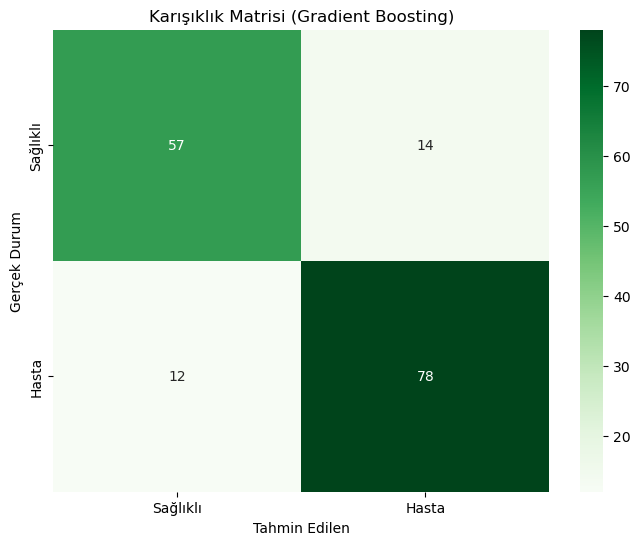

In [22]:
# -----------------------------------------------------------------------------
# ADIM 7: CONFUSION MATRIX
# -----------------------------------------------------------------------------
karmasiklik_matrisi = confusion_matrix(y_test, y_tahmin)
plt.figure(figsize=(8, 6))
sns.heatmap(karmasiklik_matrisi, annot=True, fmt='d', cmap='Greens', 
            xticklabels=["Sağlıklı", "Hasta"], yticklabels=["Sağlıklı", "Hasta"])
plt.title("Karışıklık Matrisi (Gradient Boosting)")
plt.xlabel("Tahmin Edilen")
plt.ylabel("Gerçek Durum")
plt.show()

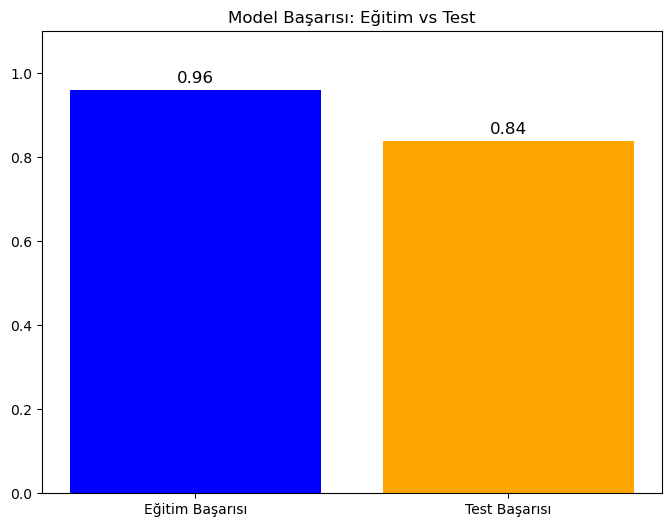

In [23]:
# -----------------------------------------------------------------------------
# ADIM 8: EĞİTİM vs TEST GRAFİĞİ
# -----------------------------------------------------------------------------
egitim_basarisi = accuracy_score(y_egitim, model.predict(X_egitim))
test_basarisi = accuracy_score(y_test, y_tahmin)

plt.figure(figsize=(8, 6))
cubuklar = plt.bar(["Eğitim Başarısı", "Test Başarısı"], 
               [egitim_basarisi, test_basarisi], color=['blue', 'orange'])
for cubuk in cubuklar:
    plt.text(cubuk.get_x() + cubuk.get_width()/2, cubuk.get_height() + 0.01, 
             round(cubuk.get_height(), 2), ha='center', va='bottom', fontsize=12)
plt.ylim(0, 1.1)
plt.title("Model Başarısı: Eğitim vs Test")
plt.show()

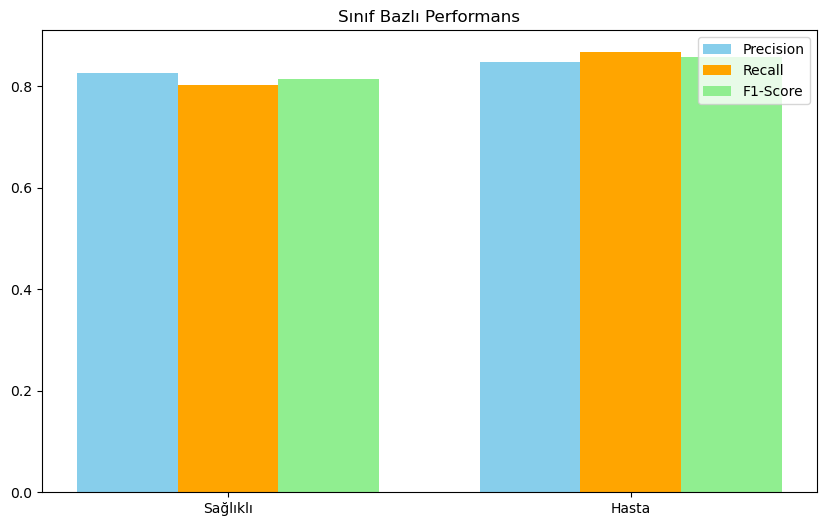

In [24]:
# -----------------------------------------------------------------------------
# ADIM 9: DETAYLI METRİKLER GRAFİĞİ
# -----------------------------------------------------------------------------
rapor = classification_report(y_test, y_tahmin, output_dict=True)
siniflar = [str(c) for c in list(rapor.keys())[:-3]]
kesinlik = [rapor[c]["precision"] for c in siniflar]
duyarlilik = [rapor[c]["recall"] for c in siniflar]
f1 = [rapor[c]["f1-score"] for c in siniflar]

x = np.arange(len(siniflar))
plt.figure(figsize=(10, 6))
plt.bar(x - 0.25, kesinlik, 0.25, label="Precision", color='skyblue')
plt.bar(x, duyarlilik, 0.25, label="Recall", color='orange')
plt.bar(x + 0.25, f1, 0.25, label="F1-Score", color='lightgreen')
plt.xticks(x, ["Sağlıklı", "Hasta"])
plt.legend()
plt.title("Sınıf Bazlı Performans")
plt.show()